# S12 · 联合重现期：AND、OR、Kendall 到底该报哪个

> **Day 12 / 14** ｜ 对应论文章节 **3.8 + 4.4（Return periods）**
>
> ⚠️ 模拟数据，结果仅用于验证流程。

---

## 学习目标

- 说清楚三种联合重现期的**定义差异**，以及它们回答的是三个不同的问题
- 避开「事件率」这个最常见的换算陷阱
- 从 copula 分位反演回「几天、几度」这种物理单位
- 用模型集成给出重现期的**区间**，而不是一个假精确的点估计

---

## 1. 三个定义，三个问题

设 $u = F_D(d)$，$v = F_I(i)$，$C$ 为 copula。

| 名称 | 公式 | 回答的问题 |
|---|---|---|
| **AND**（联合） | $T_{\wedge} = \dfrac{1}{1 - u - v + C(u,v)}$ | 「**同时**超过 d 和 i」多久一次？ |
| **OR**（联合） | $T_{\vee} = \dfrac{1}{1 - C(u,v)}$ | 「**任一**超过 d 或 i」多久一次？ |
| **Kendall** | $T_{K} = \dfrac{1}{1 - K_C(t)}$，$K_C(t)=P\big(C(U,V)\le t\big)$ | 「落在这个**危险域**里」多久一次？ |

> 📌 **三者的关系永远是** $T_{\vee} \le T_{K} \le T_{\wedge}$，而且差距随依赖增强而扩大。
>
> **论文里报哪个？** 取决于你的问题：
> - 做**风险评估 / 设计标准** → 用 **AND**（保守：两个条件都要极端才算）
> - 做**暴露统计 / 影响评估** → 用 **OR**（一个条件极端就足以致害）
> - 做**多变量极值理论的严格表述** → 用 **Kendall**（与 copula 的几何结构一致）
>
> ⚠️ 只报一个而不说明理由，是审稿人必问的问题。

---

## 2. 加载

In [1]:
for (p in c("00_setup.R", "notebooks/00_setup.R", "../00_setup.R")) {
  if (file.exists(p)) { source(p); break }
}


[00_setup.R] 已加载
  项目根目录 : C:/Users/User/Desktop/Jz/UTM/UGRP
  基准期     : 1985-2014
  阈值       : 90百分位, ±7天滑窗
  事件规则   : 最短 3 天, 合并间隔 ≤ 2 天
  干/湿切点  : ARP < 30 / > 50


In [2]:
fitres <- readRDS(file.path(PATHS$mres, "S10_copula_fits.rds"))
marg   <- readRDS(file.path(PATHS$mres, "S09_marginals.rds"))

ev <- load_catalogue()
STATION <- "Kuantan"; DEFN <- "Tmax"
e  <- ev[ev$station == STATION & ev$defn == DEFN, ]

# t copula 的 df 是拟合出来的连续值（如 20.07），而 pCopula() 只接受整数 df。
# 取整并标记 df.fixed，才能把它当成普通分布函数调用。
# （S10 的 gofCopula 碰到的是同一个限制，这里用同一个办法解决。）
as_evaluable <- function(cp) {
  if (inherits(cp, "tCopula"))
    copula::tCopula(cp@parameters[1], dim = 2,
                    df = round(cp@parameters[2]), df.fixed = TRUE)
  else cp
}

cop <- as_evaluable(fitres$copulas[[fitres$primary]])
cat("主模型:", fitres$primary, "\n")
cat("事件数:", nrow(e), "\n")

主模型: Gaussian 


事件数: 90 


---

## 3. 🚨 事件率：最容易错的一步

copula 给出的重现期单位是「**事件**」，不是「年」。

$$\text{一个 } T_{\text{事件}}\text{ 一遇的事件} \quad\Longleftrightarrow\quad T_{\text{年}} = T_{\text{事件}} / \lambda$$

其中 $\lambda$ = **每年发生多少个合格事件**。

In [3]:
d  <- load_clean_daily()
n_years <- length(unique(format(d$date, "%Y")))    # 记录长度，不是“有事件的年份数”
rate    <- nrow(e) / n_years

cat("记录长度:", n_years, "年\n")
cat("事件数  :", nrow(e), "\n")
cat("事件率 λ:", round(rate, 3), "事件/年\n")

记录长度: 44 年


事件数  : 90 


事件率 λ: 2.045 事件/年


> ⚠️ **分母必须是记录长度。**
> 常见错误是写成 `length(unique(e$start_year))` —— 那是「**至少发生过一次事件**的年份数」，
> 比记录长度小，会把 λ 算大，进而把重现期算小（低估风险）。
> 本例两者相差 10 年，λ 从 2.05 变成 2.65，**重现期被低估 23%**。

---

## 4. 求分位 q

统一采用「**u = v = q**」的口径：两个边缘取同一个分位。
这是一个**需要声明**的约定 —— AND 重现期对应的是一条等值线，不是单点，
取等分位点是文献中最常用、也最容易被解释的选择。

In [4]:
solve_q <- function(T_events, cop, type, lower = 1e-5, upper = 1 - 1e-6) {
  f <- function(q) {
    cq <- as.numeric(copula::pCopula(cbind(q, q), cop))
    if (type == "AND") 1 / (1 - 2 * q + cq) - T_events
    else               1 / (1 - cq) - T_events
  }
  tryCatch(uniroot(f, c(lower, upper), tol = 1e-10)$root,
           error = function(e) NA_real_)
}

# Kendall 重现期
Kfun  <- kendall_C_fun(cop, n = 20000)
tt    <- seq(1e-4, 1 - 1e-4, length.out = 2000)
Kapx  <- approxfun(tt, Kfun(tt), rule = 2)

solve_q_kendall <- function(T_events, cop) {
  tk <- tryCatch(uniroot(function(t) Kapx(t) - (1 - 1 / T_events),
                         c(1e-4, 1 - 1e-4))$root, error = function(e) NA_real_)
  if (is.na(tk)) return(NA_real_)
  tryCatch(uniroot(function(q) as.numeric(copula::pCopula(cbind(q, q), cop)) - tk,
                   c(1e-6, 1 - 1e-6))$root, error = function(e) NA_real_)
}

---

## 5. 反演回物理单位

In [5]:
# duration：截断几何分布的逆
F_dur <- function(d) {
  pl <- pgeom(marg$L - 1, prob = marg$p_geom)
  (pgeom(d, prob = marg$p_geom) - pl) / (1 - pl)
}
Q_dur <- function(u) {
  pl <- pgeom(marg$L - 1, prob = marg$p_geom)
  qgeom(pl + u * (1 - pl), prob = marg$p_geom)
}

# intensity：gamma 的逆
F_int <- function(i) pgamma(i, shape = marg$gamma_shape, rate = marg$gamma_rate)
Q_int <- function(u) qgamma(u, shape = marg$gamma_shape, rate = marg$gamma_rate)

# 自检：正反变换必须闭合
cat("Q_dur(F_dur(5)) =", Q_dur(F_dur(5)), " (应为 5)\n")
cat("Q_int(F_int(2)) =", round(Q_int(F_int(2)), 4), " (应为 2)\n")

Q_dur(F_dur(5)) = 5  (应为 5)


Q_int(F_int(2)) = 2  (应为 2)


---

## 6. 结果表

In [6]:
TY <- c(5, 10, 25, 50)

rp_tab <- do.call(rbind, lapply(TY, function(ty) {
  Te <- ty * rate
  qa <- solve_q(Te, cop, "AND")
  qo <- solve_q(Te, cop, "OR")
  qk <- solve_q_kendall(Te, cop)
  data.frame(
    T_years = ty,
    D_AND = Q_dur(qa), I_AND = round(Q_int(qa), 2),
    D_OR  = Q_dur(qo), I_OR  = round(Q_int(qo), 2),
    D_KEN = Q_dur(qk), I_KEN = round(Q_int(qk), 2),
    q_AND = round(qa, 4), q_OR = round(qo, 4), q_KEN = round(qk, 4)
  )
}))
print(rp_tab, row.names = FALSE)

 T_years D_AND I_AND D_OR I_OR D_KEN I_KEN  q_AND   q_OR  q_KEN
       5     5  2.08    8 2.84     6  2.24 0.7753 0.9448 0.8266
      10     6  2.36    9 3.18     7  2.51 0.8597 0.9733 0.8938
      25     7  2.69   11 3.61     8  2.85 0.9252 0.9896 0.9465
      50     8  2.93   13 3.91     9  3.11 0.9537 0.9949 0.9684


> 🔍 **先看 `q` 这一列**。`q_OR` 在 50 年时达到 0.995 ——
> 而事件样本的经验上限是 `1 − 1/(n+1) ≈ 0.989`。
> **这意味着 OR 的 50 年重现期完全是参数外推的结果**，数据没有任何一段直接支撑它。
> 这不是错误（参数化边缘的价值正在于此），但**必须写明**。
>
> 📌 论文写法：「Return levels beyond the empirical range (u > 1 − 1/(n+1)) rely on the
> parametric marginal form; results at T ≥ 25 years should therefore be read as model-based
> extrapolations rather than as data-supported quantiles.」

---

## 7. 模型不确定性：把 ΔAIC < 2 的族都算一遍

In [7]:
ens <- fitres$table$family[fitres$table$dAIC < 2]

ens_tab <- do.call(rbind, lapply(ens, function(f) {
  cp <- as_evaluable(fitres$copulas[[f]])
  do.call(rbind, lapply(c(10, 50), function(ty) {
    q <- solve_q(ty * rate, cp, "AND")
    data.frame(family = f, T_years = ty,
               D = Q_dur(q), I = round(Q_int(q), 2))
  }))
}))

print(ens_tab, row.names = FALSE)

   family T_years D    I
 Gaussian      10 6 2.36
 Gaussian      50 8 2.93
        t      10 6 2.36
        t      50 8 2.96
   Gumbel      10 6 2.43
   Gumbel      50 9 3.15


> ⚠️ **注意 `as_evaluable()` 在这里是必需的**：t copula 若保持连续 df，
> `pCopula()` 直接报错，`solve_q()` 会静默返回 `NA`（因为外面套了 `tryCatch`）。
> **静默的 NA 是最危险的 bug** —— 它不会中断，只会让集成范围悄悄缩小。
> 论文里 `df = 20` 与 `df = 20.07` 的差别可以忽略，但程序上的差别是「能算」和「不能算」。

In [8]:
ens_sum <- do.call(rbind, lapply(split(ens_tab, ens_tab$T_years), function(g)
  data.frame(T_years = g$T_years[1],
             D_min = min(g$D, na.rm = TRUE), D_max = max(g$D, na.rm = TRUE),
             I_min = min(g$I, na.rm = TRUE), I_max = max(g$I, na.rm = TRUE))))

cat("\n集成范围（AND 定义）：\n")
print(ens_sum, row.names = FALSE)


集成范围（AND 定义）：


 T_years D_min D_max I_min I_max
      10     6     6  2.36  2.43
      50     8     9  2.93  3.15


> 🚨 **这张表是 S10 §6 那个张力的兑现，同时也是对它的一次校准。**
>
> 实际结果：50 年一遇在 Gaussian / t / Gumbel 下分别是
> **8 天 · 2.93 °C / 8 天 · 2.96 °C / 9 天 · 3.15 °C** —— 有差异，但远没有 λ_U 看起来那么大。
>
> ⚠️ **这里有一个必须讲清楚的区别**：S10 里这三个族的 λ_U 是 0 / 0.011 / 0.325，
> 看上去天差地别；到了 50 年重现期却只差不到 1 天。
>
> 原因是 **λ_U 是 q → 1 的渐近量，而 50 年一遇只用到 q ≈ 0.95**。
> 尾部依赖系数描述「无限远的尾部」，重现期用到的是「比较远的尾部」—— 两者不是同一件事。
> 所以**不能**拿 λ_U 的大小去论证某个重现期一定更极端。
>
> 正确写法：「Under the ΔAIC < 2 ensemble, the 50-year AND return level ranges from
> 8 to 9 days and 2.93 to 3.15 °C. The AIC-best model provides the central estimate,
> and the ensemble range quantifies structural uncertainty. The families differ far more in
> their asymptotic tail-dependence coefficients (0–0.33) than in the 50-year quantile,
> because the latter sits at q ≈ 0.95 rather than in the asymptotic tail.」

---

## 8. 等值线图

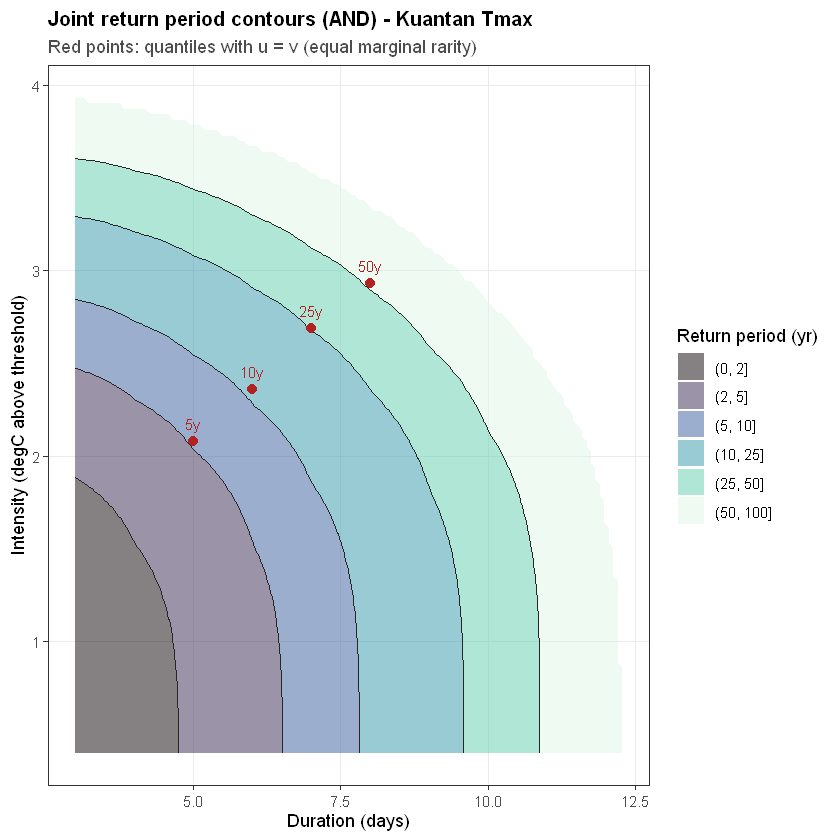

In [9]:
# F_dur 是阶梯函数（天数只能取整数），直接画图会得到锯齿状等值线。
# 仅在绘图层面对整数天做线性插值，让曲线可读；
# 表中所有数值仍用严格的离散分位数 Q_dur()。
F_dur_lin <- approxfun(1:40, F_dur(1:40), method = "linear", rule = 2)

grid <- expand.grid(d = seq(3, 15, length.out = 160),
                    i = seq(0.4, 5, length.out = 160))
grid$u <- pmin(pmax(F_dur_lin(grid$d), 1e-6), 1 - 1e-6)
grid$v <- F_int(grid$i)
grid$T_events <- T_AND(grid$u, grid$v, cop)
grid$T_years  <- pmin(grid$T_events / rate, 100)

p_rp <- ggplot(grid, aes(d, i, z = T_years)) +
  geom_contour_filled(breaks = c(0, 2, 5, 10, 25, 50, 100), alpha = 0.5) +
  geom_contour(breaks = c(2, 5, 10, 25, 50), colour = "grey15", linewidth = 0.5) +
  geom_point(data = rp_tab, aes(D_AND, I_AND, z = NULL),
             inherit.aes = FALSE, size = 2.4, colour = "firebrick") +
  geom_text(data = rp_tab, aes(D_AND, I_AND, label = paste0(T_years, "y"), z = NULL),
            inherit.aes = FALSE, vjust = -1, size = 3.2, colour = "firebrick") +
  scale_fill_viridis_d(option = "mako", direction = 1, name = "Return period (yr)") +
  labs(x = "Duration (days)", y = "Intensity (degC above threshold)",
       title = paste("Joint return period contours (AND) -", STATION, DEFN),
       subtitle = "Red points: quantiles with u = v (equal marginal rarity)") +
  theme_paper() + theme(legend.position = "right")

save_fig(p_rp, "S12_return_period_contours", 7.2, 4.8)
p_rp

> 🔍 **为什么原始版本画出来是锯齿？** 因为 `duration` 的边缘是**阶梯函数** ——
> 天数从 3 变到 4，`F_dur` 才跳一次。等值线在每两级台阶之间必然是垂直段。
> 这不是 bug，是离散变量的固有形状；出图时做一次线性插值只是为了让读者看得清**趋势**，
> 列在表里的数字仍然严格来自 `Q_dur()`。
>
> **论文里如果要放这张图，图注必须写**：「Contours are smoothed between integer durations for display;
> all tabulated return levels use the exact discrete duration quantile.」

> 🔍 **等值线图读法**：沿一条等值线，时长增加可以换取强度降低 ——
> 这是**权衡（trade-off）关系**，也正是为什么「一个重现期」不能对应「一个事件」。
> 论文里说「50 年一遇的热浪是 8 天」，隐含了「在等分位口径下」这个前提，必须写出。

---

## 9. 敏感性：三种定义差多少

In [10]:
cmp <- rp_tab[, c("T_years", "D_AND", "D_OR", "D_KEN", "I_AND", "I_OR", "I_KEN")]
print(cmp, row.names = FALSE)

cat("\nT = 10 年时：\n")
cat("  AND 定义 -> ", rp_tab$D_AND[2], " 天 /", rp_tab$I_AND[2], "degC\n")
cat("  Kendall  -> ", rp_tab$D_KEN[2], " 天 /", rp_tab$I_KEN[2], "degC\n")
cat("  OR  定义 -> ", rp_tab$D_OR[2],  " 天 /", rp_tab$I_OR[2],  "degC\n")

 T_years D_AND D_OR D_KEN I_AND I_OR I_KEN
       5     5    8     6  2.08 2.84  2.24
      10     6    9     7  2.36 3.18  2.51
      25     7   11     8  2.69 3.61  2.85
      50     8   13     9  2.93 3.91  3.11



T = 10 年时：


  AND 定义 ->  6  天 / 2.36 degC


  Kendall  ->  7  天 / 2.51 degC


  OR  定义 ->  9  天 / 3.18 degC


> 📌 同一份数据、同一个 copula，只因定义不同，10 年一遇事件的时长可以从 6 天变到 9 天。
> **这就是为什么方法章必须明确写「本研究采用 AND 定义，理由如下……」**，
> 而不是含糊地写「计算了联合重现期」。

---

## 10. 保存

In [11]:
write.csv(rp_tab, file.path(PATHS$mres, "table5_return_periods.csv"), row.names = FALSE)
write.csv(ens_tab, file.path(PATHS$mres, "table5b_ensemble.csv"), row.names = FALSE)
cat("已保存 table5_return_periods.csv 与 table5b_ensemble.csv\n")

已保存 table5_return_periods.csv 与 table5b_ensemble.csv


---

## 11. 常见错误

| 错误 | 后果 |
|---|---|
| 用「有事件的年份数」算事件率 | λ 偏大，重现期被低估 |
| 直接把 copula 的 T 当年重现期 | 差一个 λ 的倍数 |
| 只报一种定义且不说明理由 | 审稿人必问 |
| 报告超出经验范围的分位却不声明外推 | 结论强度被高估 |
| 只报 AIC 最优模型的重现期 | 隐藏结构不确定性 |
| 把「50 年一遇」当成「每 50 年必然发生一次」 | 概率语言误用（它是年超越概率 1/50） |
| 用 u=v 求单点却不说明 | 读者以为等值线上每点都一样 |

---

## 12. 自检问题

<details>
<summary>Q1：为什么 T_OR ≤ T_Kendall ≤ T_AND？</summary>

「任一超过」的集合最大，最容易被触发，所以重现期最短；「同时超过」的集合最小，最难触发，重现期最长。Kendall 测度的是危险域的测度，介于两者之间。依赖越强，三者差距越大；完全独立时 AND 与 OR 会趋于一致。

</details>

<details>
<summary>Q2：50 年一遇的意思是「50 年内一定发生一次」吗？</summary>

不是。它是**年超越概率 1/50 = 2%**。50 年内至少发生一次的概率是 1 − (1 − 0.02)^50 ≈ 64%。这个区别在写影响评估时至关重要。

</details>

<details>
<summary>Q3：如果 q_OR = 0.995 而样本最大分位是 0.989，这个结果还能报吗？</summary>

能报，但必须标注为**模型外推**，并在讨论里说明它对边缘分布形式的敏感性。诚实的做法是同时给出：参数外推值 + 经验上限处的结果 + 一句「超出此范围的结果应谨慎解读」。审稿人接受有边界的结论，不接受无边的自信。

</details>

<details>
<summary>Q4：为什么要求 u = v？不能取别的点吗？</summary>

能。AND 重现期对应的是一条等值线，线上每一点都有相同的 T，但对应不同的 (D, I) 组合。取 u = v 是最常用的约定（「两个边缘同样罕见」），也最好解释。另一种做法是取条件期望最大的点（most likely event），但那需要额外的假设。**关键是写明你选了哪个。**

</details>

<details>
<summary>Q5：事件率 λ 会不会随时间变化？</summary>

会。气候变暖下超阈值事件率在上升，用全期平均 λ 等于假设非平稳性可以忽略。这是 S14 要处理的问题之一（时变阈值 + 分段事件率）。在 S12 阶段先明确声明这个简化。

</details>

---

## 下一步

**S13 · 排序分歧（RDI）**：三套定义给出的风险排序一致吗？
如果不一致，「用哪个定义」就会改变哪些站点被列为高风险 —— 这直接关系到防灾资源的分配。